In [1]:
import nbformat
notebook_file = "main.ipynb"
with open(notebook_file, "r", encoding="utf-8") as file:
    notebook = nbformat.read(file, as_version=4)
anzahl_woerter = 0
for cell in notebook.cells:
    if cell.cell_type == "markdown":
        # Count words in the markdown cell
        words_in_cell = len(cell.source.split())
        anzahl_woerter += words_in_cell
print(anzahl_woerter)

1174


<span style="margin:auto; display:table;color:black;font-size:18px;font-family:Arial">Fachhochschule Südwestfalen</span>

<span style="margin:auto; display:table;color:black;font-size:18px;font-family:Arial">Semesterabschließende schriftliche Ausarbeitung im Modul Machine Learning (SS2023)</span>

<span style="margin:auto; display:table;color:black;font-size:30px;font-family:Arial"><br><br> <br>
</span>

<span style="margin:auto; display:table;color:black;font-size:18px;font-family:Arial"><br><br><br><br>Bearbeitet von Richard Keppler</span>

<span style="margin:auto; display:table;color:black;font-size:18px;font-family:Arial"><br>23. Juli 2023</span>

# Inhaltsverzeichnis

1. [Einleitung](#einleitung)
2. [Vorbereitungen](#vorbereitungen)
3. [Statistische Auswertung und Visualisierung](#visualisierung)
4. [Preprocessing](#preprocessing)
5. [Testing](#testing)
   1. [Anzahl der Layers](#anzahl)
   2. [Sampling](#sampling)
   3. [Hyperparameter](#hyperparameter)
6. [Auswertung](#auswertung)
7. [Quellen](#quellen)

<a name="einleitung"></a>
## 1. Einleitung

Die vorliegende Ausarbeitung hat zum Ziel, anhand der Röntgenbildern von menschlichen Lungen Aussagen über unterschiedliche Arten von Lungenkrankheiten treffen zu können. Dazu soll ein Modell zur Bilderkennung trainiert werden, das diese Aussagen möglichst mit hoher Wahrscheinlichkeit korrekt durchführt. Die Daten, mithilfe derer das Modell trainiert und evaluiert wird, stammen dabei von kaggle.com. Der Datensatz "COVID-19 Radiography Database" umfasst insgesamt 21165 Bilder, die jeweils in ungleicher Anzahl in die vier Kategorien "Normal", "Viral Pneumonia", "Lung Opacity" und "Covid-19" eingeteilt werden, wobei die Röntgenbilder keine oder jeweils eine der drei Lungenkrankenheiten zeigen.
Das Modell soll mithilfe eines sogenannten "Convolutional Neural Network" (CNN) trainiert werden, das ein Konzept im Bereich des maschinellen Lernens darstellt. Ein CNN ist ein  [1]

<a name="vorbereitungen"></a>
## 2. Vorbereitungen

Ein grober Überblick über den Datensatz wird sich in Kapitel 2 verschafft, wobei diese dann in jeweils noch in verschiedenen Ordnern gespeichert werden.

Die vorliegenden Daten sind, je nach Label sortiert, in insgesamt vier Ordnern abgelegt, wobei alle Bilder die Größe 256x256 Pixel haben und fortlaufend nummeriert sind. Ebenfalls sind im Datensatz zu jedem Label .xls-Dateien enthalten, die Metadaten zu den Bildern enthalten, im weiteren Verlauf aber nicht weiter berücksichtigt werden.

Es werden die verschiedenen Bibliotheken importiert, die im weiteren Verlauf genutzt werden. Hervorzuheben sind hier insbesondere die Bibliotheken "Imbalanced-learn" und "TensorFlow", die jeweils zum "Ausbalancieren" der Trainingsdaten bzw. zum anschließenden Training des CNN Anwendung finden.

In [2]:
import os
import shutil
import random
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.utils import to_categorical
from keras.preprocessing.image import ImageDataGenerator
import time
import albumentations as A
from tabulate import tabulate
from albumentations.pytorch import ToTensorV2
from tensorflow.python.keras import Sequential
from tensorflow.python.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

Zunächst wird die Anzahl der Bilder in den jeweiligen Ordnern ausgegeben, um eine Übersicht zu erhalten und um sicherzustellen, dass deren Anzahl im weiteren Verlauf konstant bleibt.

In [3]:
print('Anzahl der Bilder im Ordner \'Normal\': ', len(os.listdir('COVID-19_Radiography_Dataset/Normal/images')))
print('Anzahl der Bilder im Ordner \'Covid\': ', len(os.listdir('COVID-19_Radiography_Dataset/COVID/images')))
print('Anzahl der Bilder im Ordner \'Lung Opacity\': ', len(os.listdir('COVID-19_Radiography_Dataset/Lung_Opacity/images')))
print('Anzahl der Bilder im Ordner \'Viral Pneumonia\': ', len(os.listdir('COVID-19_Radiography_Dataset/Viral Pneumonia/images')))
print('Gesamtanzahl aller Bilder: ', len(os.listdir('COVID-19_Radiography_Dataset/Normal/images')) + len(os.listdir('COVID-19_Radiography_Dataset/COVID/images')) + len(os.listdir('COVID-19_Radiography_Dataset/Lung_Opacity/images')) + len(os.listdir('COVID-19_Radiography_Dataset/Viral Pneumonia/images')))

Anzahl der Bilder im Ordner 'Normal':  10192
Anzahl der Bilder im Ordner 'Covid':  3616
Anzahl der Bilder im Ordner 'Lung Opacity':  6012
Anzahl der Bilder im Ordner 'Viral Pneumonia':  1345
Gesamtanzahl aller Bilder:  21165


Wie bereits beschrieben, liegen die Bilder gespeichert in den Ordnern mit den jeweiligen Labels als Ordnername vor. Um mit dem Datensatz besser arbeiten zu können, werden alle Bilder kopiert und in den Ordnern "train", "test" und "val" im Unterordner "train_data" abgelegt, wobei 70 % der Bilder zum Trainieren, 20 % der Bilder zum Testen und 10 % der Bilder zum Evaluieren genutzt werden. Zur Kontrolle wird die Anzahl der einzelnen Bilder nach Label ausgegeben.

In [4]:
classes_dictionary = {'NORMAL': 'Normal', 'COVID': 'COVID', 'LUNG OPACITY': 'Lung_Opacity', 'VIRAL PNEUMONIA': 'Viral Pneumonia'}
def copy_images_to_directory(images, labels, dest_dir):
    for i, (image, label) in enumerate(zip(images, labels)):
        label_dir = os.path.join(dest_dir, label)
        os.makedirs(label_dir, exist_ok=True)
        filename = f"{label}_{i}.jpg"
        dest_path = os.path.join(label_dir, filename)
        shutil.copy(image, dest_path)
data_folder = 'COVID-19_Radiography_Dataset'
dest_dir = data_folder
os.makedirs(os.path.join(data_folder, 'train_data', 'train'), exist_ok=True)
os.makedirs(os.path.join(data_folder, 'train_data', 'test'), exist_ok=True)
os.makedirs(os.path.join(data_folder, 'train_data', 'val'), exist_ok=True)
label_counts = {}
for class_name, folder_name in classes_dictionary.items():
    images = []
    labels = []
    class_folder = os.path.join(data_folder, folder_name, 'images')
    for image_file in os.listdir(class_folder):
        images.append(os.path.join(class_folder, image_file))
        labels.append(class_name)
    labels = [label.lower() for label in labels]
    label_counts[folder_name] = len(images)
    combined_data = list(zip(images, labels))
    random.shuffle(combined_data)
    images[:], labels[:] = zip(*combined_data)
    total_images = len(images)
    val_counts = int(total_images * 0.1)
    test_counts = int(total_images * 0.2)
    train_counts = total_images - val_counts - test_counts
    X_train, X_test = images[val_counts+test_counts:], images[val_counts:val_counts+test_counts]
    y_train, y_test = labels[val_counts+test_counts:], labels[val_counts:val_counts+test_counts]
    X_val, _ = images[:val_counts], images[val_counts:val_counts+test_counts]
    y_val, _ = labels[:val_counts], labels[val_counts:val_counts+test_counts]
    dest_train_dir = os.path.join(dest_dir, 'train_data', 'train')
    dest_test_dir = os.path.join(dest_dir, 'train_data', 'test')
    dest_val_dir = os.path.join(dest_dir, 'train_data', 'val')
    copy_images_to_directory(X_train, y_train, dest_train_dir)
    copy_images_to_directory(X_test, y_test, dest_test_dir)
    copy_images_to_directory(X_val, y_val, dest_val_dir)
class_names = classes_dictionary.keys()
for class_name in class_names:
    count = label_counts[classes_dictionary[class_name]]
    print(f"{class_name}: {count}")

NORMAL: 10192
COVID: 3616
LUNG OPACITY: 6012
VIRAL PNEUMONIA: 1345


<a name="visualisierung"></a>
## 3. Statistische Auswertung und Visualisierung

Eine statistische Auswertung und Visualisierung der vorliegenden Daten wird in Kapitel 3 durchgeführt. Dies dient dazu einen Überblick über den Datensatz und die Verteilung der Bilder in den einzelnen Kategorien zu erhalten.

Zur besseren Veranschaulichung werden jeweils zwei zufällig ausgewählte Bilder sortiert nach Label aus den Ordnern "train", "test" und "val" ausgegeben. Zur Überprüfung wird ebenfalls noch einmal die Gesamtanzahl aller Bilder ausgegeben.

In [5]:
classes = list(classes_dictionary.keys())
path_meta = "COVID-19_Radiography_Dataset/train_data/"
path_train_normal = os.path.join(path_meta, 'train/normal')
path_train_covid = os.path.join(path_meta, 'train/covid')
path_train_lung_opacity = os.path.join(path_meta, 'train/lung opacity')
path_train_viral_pneumonia = os.path.join(path_meta, 'train/viral pneumonia')
path_test_normal = os.path.join(path_meta, 'test/normal')
path_test_covid = os.path.join(path_meta, 'test/covid')
path_test_lung_opacity = os.path.join(path_meta, 'test/lung opacity')
path_test_viral_pneumonia = os.path.join(path_meta, 'test/viral pneumonia')
path_val_normal = os.path.join(path_meta, 'val/normal')
path_val_covid = os.path.join(path_meta, 'val/covid')
path_val_lung_opacity = os.path.join(path_meta, 'val/lung opacity')
path_val_viral_pneumonia = os.path.join(path_meta, 'val/viral pneumonia')

In [6]:
len_normal = len(os.listdir(path_train_normal)) + len(os.listdir(path_test_normal)) + len(os.listdir(path_val_normal))
len_covid = len(os.listdir(path_train_covid)) + len(os.listdir(path_test_covid)) + len(os.listdir(path_val_covid))
len_lung_opacity  = len(os.listdir(path_train_lung_opacity)) + len(os.listdir(path_test_lung_opacity)) + len(os.listdir(path_val_lung_opacity))
len_viral_pneumonia = len(os.listdir(path_train_viral_pneumonia)) + len(os.listdir(path_test_viral_pneumonia)) + len(os.listdir(path_val_viral_pneumonia))
len_train = len(os.listdir(path_train_normal)) + len(os.listdir(path_train_covid)) + len(os.listdir(path_train_lung_opacity)) + len(os.listdir(path_train_viral_pneumonia))
len_test = len(os.listdir(path_test_normal)) + len(os.listdir(path_test_covid)) + len(os.listdir(path_test_lung_opacity)) + len(os.listdir(path_test_viral_pneumonia))
len_val = len(os.listdir(path_val_normal)) + len(os.listdir(path_val_covid)) + len(os.listdir(path_val_lung_opacity)) + len(os.listdir(path_train_viral_pneumonia))
len_categories = [len_normal, len_covid, len_lung_opacity, len_viral_pneumonia]
print(f"Gesamtanzahl aller Bilder: {len_normal + len_covid + len_lung_opacity + len_viral_pneumonia}")

Gesamtanzahl aller Bilder: 21165


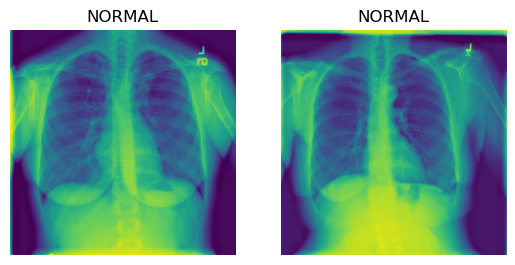

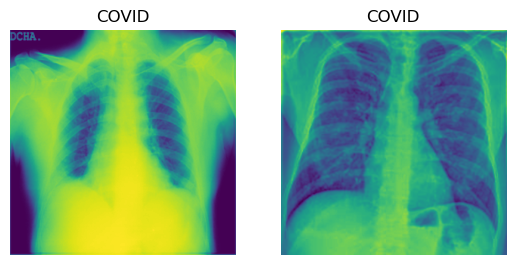

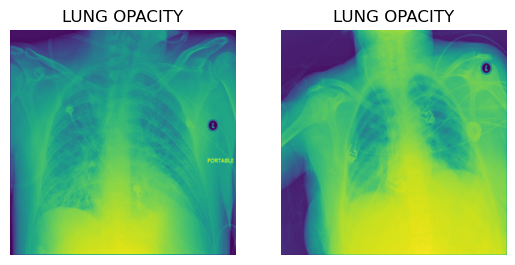

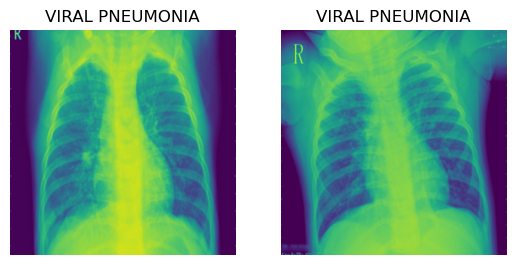

In [7]:
def show_images(img_folder, class_img):
    img_list = []
    img_files = os.listdir(img_folder)
    for img in img_files:
        img_list.append(img)
    if len(img_list) < 2:
        print(f'Es gibt weniger als 2 Bilder im Verzeichnis.')
    random_images_number = random.sample(img_list, 2)
    random_image_1 = Image.open(os.path.join(img_folder, random_images_number[0]))
    random_image_2 = Image.open(os.path.join(img_folder, random_images_number[1]))
    plt.subplot(1, 2, 1)
    plt.imshow(random_image_1)
    plt.title(class_img)
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(random_image_2)
    plt.title(class_img)
    plt.axis('off')
    plt.show()
show_images(path_train_normal, classes[0])
show_images(path_train_covid, classes[1])
show_images(path_train_lung_opacity, classes[2])
show_images(path_train_viral_pneumonia, classes[3])

Um eine Übersicht über die Daten innerhalb des Datensatzes zu erhalten, werden verschiedene Merkmale statistisch ausgewertet und in Diagrammen dargestellt. Aus der Abbildung "Anzahl der Röntgenbilder nach Label" ist zu erkennen, dass die die Anzahl der einzelnen Bilder, sortiert nach Label, ungleich verteilt ist, sodass beispielsweise die Anzahl der Bilder mit dem Label "normal" mehr als siebenfach so hoch ist wie die Anzahl der Bilder mit dem Label "Viral Pneumonia". Dieser Sachverhalt lässt sich ebenso aus dem Diagramm "Prozentuale Verteilung der Daten nach Label" ableiten, das die prozentuale Verteilung der Daten darstellt. Das Kreisdiagramm "Prozentuale Verteilung der Daten nach Split" zeigt die prozentuale Verteilung der Trainings-, Test- und Validierungsdaten. Da die Daten vor dem Aufteilen in Trainings-, Test- und Validierungsdaten gemischt und anschließend auf diese aufgeteilt werden, kann die prozentuale Verteilung leicht abweichen, was jedoch vernachlässigbar ist.

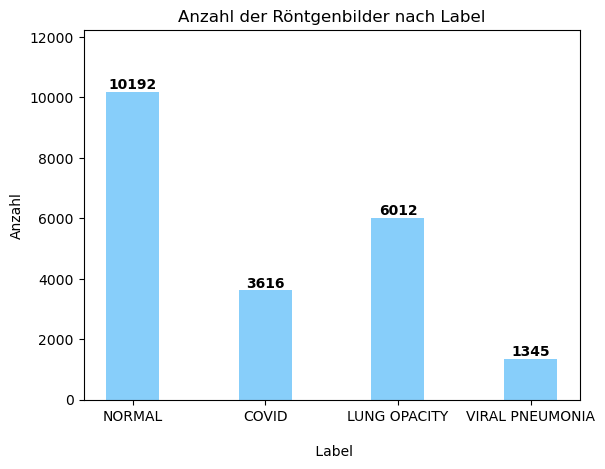

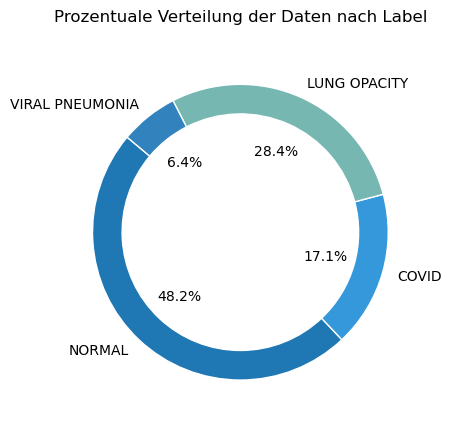

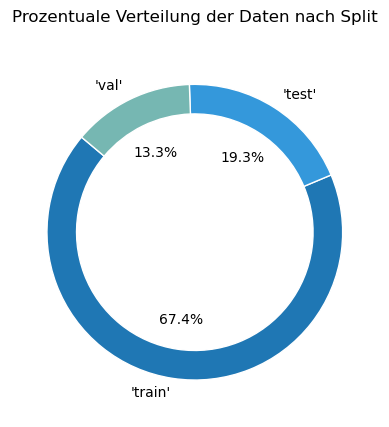

In [8]:
plt.bar(classes, len_categories, width=0.4, color='lightskyblue', align='center')
plt.xlabel('\n Label')
plt.ylabel('Anzahl')
plt.title('Anzahl der Röntgenbilder nach Label')
for i, v in enumerate(len_categories):
    plt.text(i, v, str(v), ha='center', va='bottom', fontweight='bold')
plt.ylim(0, max(len_categories)*1.2)
plt.show()
colors1 = ['#1f77b4', '#3498db', '#76b7b2', '#3182bd']
summe = len_normal + len_covid + len_lung_opacity + len_viral_pneumonia
prozentwert_normal = summe / 100 * len_normal
prozentwert_covid = summe / 100 * len_covid
prozentwert_lung_opacity = summe / 100 * len_lung_opacity
prozentwert_viral_pneumonia = summe / 100 * len_viral_pneumonia
sizes = [prozentwert_normal, prozentwert_covid, prozentwert_lung_opacity, prozentwert_viral_pneumonia]
plt.pie(sizes, labels=classes, autopct='%1.1f%%', colors=colors1, startangle=140, wedgeprops=dict(width=0.2, edgecolor='w'))
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
plt.title('Prozentuale Verteilung der Daten nach Label\n')
plt.show()
colors2 = ['#1f77b4', '#3498db', '#76b7b2']
summe2 = len_train + len_test + len_val
prozentwert_train = len_train / summe2 * 100
prozentwert_test = len_test /summe2 * 100
prozentwert_val = len_val / summe2 * 100
sizes2 = [prozentwert_train, prozentwert_test, prozentwert_val]
plt.pie(sizes2, labels=['\'train\'', '\'test\'', '\'val\''], autopct='%1.1f%%', colors=colors2, startangle=140, wedgeprops=dict(width=0.2, edgecolor='w'))
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
plt.title('Prozentuale Verteilung der Daten nach Split\n')
plt.show()

<a name="preprocessing"></a>
## 4. Preprocessing

In diesem Kapitel werden die Bilder und Labels mittels verschiedener Methoden vorverarbeitet, um so verschiedene  und die .

Die Bilder und deren Labels werden als numpy-Array gespeichert, um sie schneller verarbeiten zu können und diese in den Variablen train_images, train_labels, val_images, val_labels, test_images und test_labels abgelegt. Es ist zu beachten, dass die Arrays der Bilder "normalisiert", das heißt durch die Differenz der maximalen und der minimalen Pixelanzahl (255) dividiert werden, um mit diesen effizienter arbeiten zu können. Ebenfalls werden in diesem Schritt die Bilder von 256 x 256 Pixel auf 200 x 200 Pixel skaliert, um den Lernprozess aufgrund der großen Datenmengen ebenfalls effizienter zu gestalten, gleichzeitig aber noch genügend Informationen zu behalten. Die RGB-Farbgebung der Bilder soll aufgrund der schnelleren Verarbeitung der Daten ebenfalls in Grauwerte umgewandelt werden. Ebenfalls werden den Labeln jeweils numerische Werte zugeordnet, um Speicherplatz zu sparen und den Lernprozess effizienter zu gestalten.

In [7]:
def load_images_into_arrays(data_folder, subset):
    images = []
    labels = []
    label_mapping = {'normal': 0, 'covid': 1, 'lung opacity': 2, 'viral pneumonia': 3}
    subset_folder = os.path.join(data_folder, subset)
    image_size = (200, 200)
    for label_folder in os.listdir(subset_folder):
        label_index = label_mapping.get(label_folder.lower(), -1)
        if label_index != -1:
            label_folder_path = os.path.join(subset_folder, label_folder)
            for image_file in os.listdir(label_folder_path):
                image_path = os.path.join(label_folder_path, image_file)
                image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
                image = cv2.resize(image, image_size)
                image = image.astype(np.float32) / 255.0
                images.append(image)
                labels.append(label_index)
    max_height = image_size[0]
    max_width = image_size[1]
    for i in range(len(images)):
        image = images[i]
        padded_image = np.zeros((max_height, max_width, 1), dtype=np.float32)
        padded_image[:image.shape[0], :image.shape[1], 0] = image
        images[i] = padded_image
    images_array = np.array(images)
    labels_array = np.array(labels)
    return images_array, labels_array
train_images, train_labels = load_images_into_arrays(path_meta, 'train')
val_images, val_labels = load_images_into_arrays(path_meta, 'val')
test_images, test_labels = load_images_into_arrays(path_meta, 'test')
num_train_images = train_images.shape[0]
num_test_images = test_images.shape[0]
num_val_images = val_images.shape[0]
print("Anzahl der Trainingsbilder:", num_train_images)
print("Anzahl der Testbilder:", num_test_images)
print("Anzahl der Validierungsbilder:", num_val_images)

Anzahl der Trainingsbilder: 14818
Anzahl der Testbilder: 4232
Anzahl der Validierungsbilder: 2115


Die in der Variable train_images gespeicherten Bildarrays werden anschließend augmentiert, um Overfitting zu verhindern und somit die Robustheit des Modells, also die Fähigkeit, genaue Vorhersagen auf neuen, bisher unbekannten Daten, zu verbessern. Das Overfitting beschreibt ein Phänomen, bei dem ein Modell so stark auf die Trainingsdaten angepasst wird, sodass Komplikationen beim Verarbeiten von neuen, unbekannten Daten auftreten, da das Modell anschließend zu stark auf die Trainingsdaten angepasst ist [2]. Da die Bilder jedoch relativ gleichartig vorliegen, das heißt ähnlich sind in ihrem Aussehen und nur ein Overfitting verhindert werden soll, werden nur 50 % der Trainingsdaten augmentiert. Es ist jedoch darauf zu achten, dass jeweils 50 % der Daten jeder Kategorie und nicht die erste Hälfte oder zweite Hälfte des gesamten Arrays augmentiert wird. Zur Augmentation der Daten wird die Bibliothek "albumentations" genutzt, mittels derer die Bilder rotiert, verschoben und horizontal gespiegelt werden. Die Bilder werden anschließend ebenfalls zu den unbearbeiteten Bildern hinzugefügt. Das Format der Arrays der Labels wird dabei noch nach dem sogenannten "One-hot encoding"-Verfahren verändert. In diesem Format werden die Bilder von einer kategorialen Variable in einen binären Vektor umgewandelt, um diesen anschließend leichter verarbeiten zu können.

In [8]:
# Defining the augmentation pipeline using Albumentations
augmentation_pipeline = A.Compose([
    A.Rotate(limit=20, p=0.5),
    A.ShiftScaleRotate(shift_limit=0.2, scale_limit=0.2, rotate_limit=20, p=0.5),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.2),
])

num_classes = 4
augmentation_percentage = 0.5

augmented_images = []
augmented_labels = []

for class_index in range(num_classes):
    class_indices = np.where(train_labels == class_index)[0]
    class_images = train_images[class_indices]
    num_augmented_images = int(len(class_images) * augmentation_percentage)

    aug_images = []
    for i in range(num_augmented_images):
        image = class_images[i]
        augmented = augmentation_pipeline(image=image)
        aug_images.append(augmented['image'])
        augmented_labels.append(class_index)

    augmented_images.extend(aug_images)

# Convert augmented images to a numpy array
augmented_images_array = np.array(augmented_images)

# Stack the original and augmented images
final_train_images = np.vstack((train_images, augmented_images_array))

# Create labels for the augmented images
augmented_labels_array = np.array(augmented_labels)
final_train_labels = np.hstack((train_labels, augmented_labels_array))

# Convert labels to one-hot encoding
final_train_labels_one_hot = to_categorical(final_train_labels, num_classes)

print('Number of augmented images:', len(augmented_images))
print('Total number of training images:', len(final_train_images))

Number of augmented images: 7408
Total number of training images: 22226


Den einzelnen Labels der verschiedenen Klassen werden jeweils die folgenden numerische Werte zugeordnet, die zur besseren Übersicht noch einmal angezeigt werden sollen.

In [ ]:
labels = ['0', '1', '2', '3']
print(f'Label für Klasse \'{classes[0]}\':', labels[0])
print(f'Label für Klasse \'{classes[1]}\':', labels[1])
print(f'Label für Klasse \'{classes[2]}\':', labels[2])
print(f'Label für Klasse \'{classes[3]}\':', labels[3])

Zur Überprüfung der Augmentierung werden zufällig jeweils drei Bilder aus den Trainingsdaten inklusive ihres jeweiligen Labels ausgegeben.

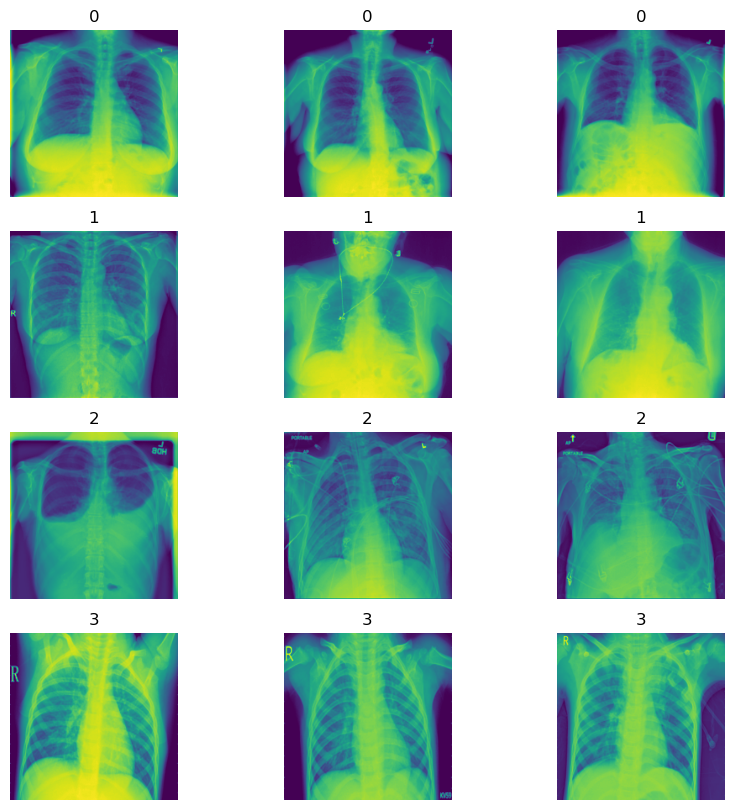

In [12]:
fig, axes = plt.subplots(len(class_names), 3, figsize=(10, 10))
for i, class_name in enumerate(class_names):
    class_indices = np.where(train_labels == i)[0]
    random_indices = random.sample(list(class_indices), 3)
    random_images = final_train_images[random_indices]
    for j in range(3):
        axes[i, j].imshow(random_images[j])
        axes[i, j].set_title(f'{i}')
        axes[i, j].axis('off')
plt.show()

Es werden nun ebenfalls die Variablen y_test und y_val mittels der "Hot-Encoding"-Methode entsprechend geändert.

In [9]:
y_val_one_hot = to_categorical(val_labels, num_classes)
y_test_one_hot = to_categorical(test_labels, num_classes)

Die Arrays der Bilder und der Labels werden in den finalen Variablen X_train, y_train, X_val, y_val, X_test und y_test abgelegt und zur Überprüfung der korrekten Form wird diese für jede einzelne Variable noch einmal ausgegeben.

In [10]:
X_train, y_train = final_train_images, final_train_labels_one_hot
X_val, y_val = val_images, y_val_one_hot
X_test, y_test = test_images, y_test_one_hot
print('Form des Arrays \'X_train\':', X_train.shape)
print('Form des Arrays \'y_train\':', y_train.shape)
print('Form des Arrays \'X_test\':', X_test.shape)
print('Form des Arrays \'y_test\':', y_test.shape)
print('Form des Arrays \'X_val\':', X_val.shape)
print('Form des Arrays \'y_val\':', y_val.shape)

Form des Arrays 'X_train': (22226, 200, 200, 1)
Form des Arrays 'y_train': (22226, 4)
Form des Arrays 'X_test': (4232, 200, 200, 1)
Form des Arrays 'y_test': (4232, 4)
Form des Arrays 'X_val': (2115, 200, 200, 1)
Form des Arrays 'y_val': (2115, 4)


<a name="testing"></a>
## 5. Testing

In diesem Kapitel sollen verschiedene Parameter des Modells geändert werden, um so deren Einflüsse auf dieses Modell herauszufinden. Ziel dieses Kapitels soll es sein, sukzessive das hinsichtlich seiner Genauigkeit optimalste Modell zu finden.

<a name="anzahl"></a>
### 5.1 Anzahl der Layers

Die Funktion "train_and_plot_layers" wird definiert, um gewisse Parameter zu testen und darzustellen.

In [11]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=7)

def train_and_plot_layers(X_train, y_train, X_val, y_val, X_test, y_test, model):
    # Training
    history = model.fit(X_train, y_train, batch_size=32, epochs=50, validation_data=(X_val, y_val), callbacks=[early_stopping])

    # Evaluation on test set
    test_loss, test_accuracy = model.evaluate(X_test, y_test)

    print('Test Loss:', test_loss)
    print('Test Accuracy:', test_accuracy)

     # Accuracy in a graph
    plt.figure(figsize=(12, 6))
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')  # Validation Accuracy in orange
    plt.axhline(test_accuracy, color='r', linestyle='dashed', label='Test Accuracy')  # Horizontal line for test accuracy
    plt.title('Training, Validation, and Test Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

    # Loss in a graph
    plt.figure(figsize=(12, 6))
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')  # Validation Loss in orange
    plt.axhline(test_loss, color='r', linestyle='dashed', label='Test Loss')  # Horizontal line for test loss
    plt.title('Training, Validation, and Test Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.ylim([0, 3])
    plt.legend()
    plt.show()

2023-08-03 23:45:14.380522: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-08-03 23:45:15.643633: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1613] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 54232 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:c1:00.0, compute capability: 8.0


Epoch 1/50


2023-08-03 23:45:22.314829: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:428] Loaded cuDNN version 8500
2023-08-03 23:45:24.174808: I tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:630] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2023-08-03 23:45:24.183305: I tensorflow/compiler/xla/service/service.cc:173] XLA service 0x560e2c3fab50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2023-08-03 23:45:24.183349: I tensorflow/compiler/xla/service/service.cc:181]   StreamExecutor device (0): NVIDIA A100-SXM4-80GB, Compute Capability 8.0
2023-08-03 23:45:24.190185: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2023-08-03 23:45:24.317244: I tensorflow/compiler/jit/xla_compilation_cache.cc:477] Compiled cluster using XLA!  This line is logged at most once for the lifetime of th

695/695 [==============================] - 41s 47ms/step - loss: 1.7706 - accuracy: 0.6795 - val_loss: 1.4299 - val_accuracy: 0.4695
Epoch 2/50
695/695 [==============================] - 29s 41ms/step - loss: 0.5502 - accuracy: 0.7866 - val_loss: 0.8417 - val_accuracy: 0.6397
Epoch 3/50
695/695 [==============================] - 28s 40ms/step - loss: 0.4560 - accuracy: 0.8239 - val_loss: 0.7010 - val_accuracy: 0.7466
Epoch 4/50
695/695 [==============================] - 36s 51ms/step - loss: 0.4265 - accuracy: 0.8341 - val_loss: 2.0852 - val_accuracy: 0.4667
Epoch 5/50
695/695 [==============================] - 30s 43ms/step - loss: 0.3828 - accuracy: 0.8538 - val_loss: 1.2563 - val_accuracy: 0.4917
Epoch 6/50
695/695 [==============================] - 27s 39ms/step - loss: 0.3393 - accuracy: 0.8717 - val_loss: 1.4829 - val_accuracy: 0.3626
Epoch 7/50
695/695 [==============================] - 33s 47ms/step - loss: 0.2984 - accuracy: 0.8850 - val_loss: 0.5347 - val_accuracy: 0.8113
Epo

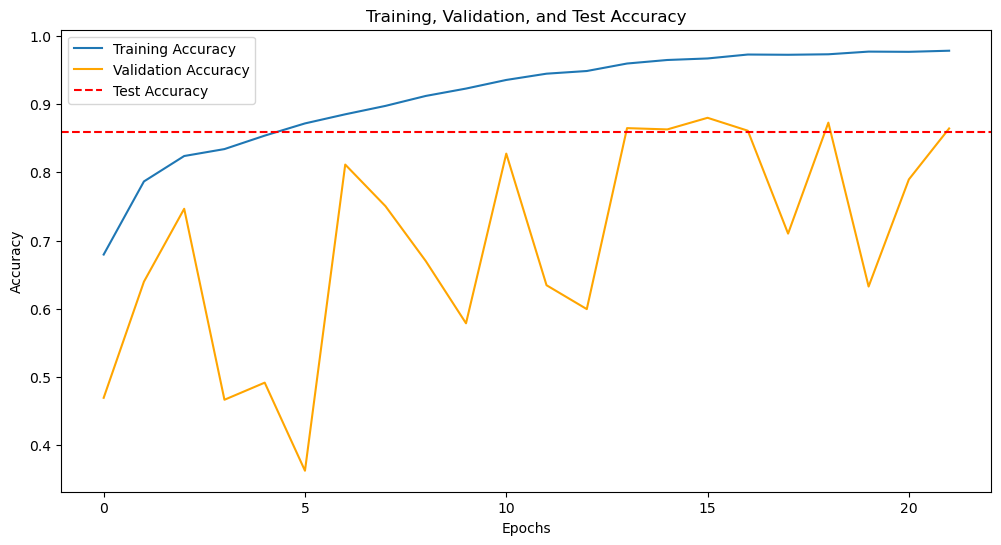

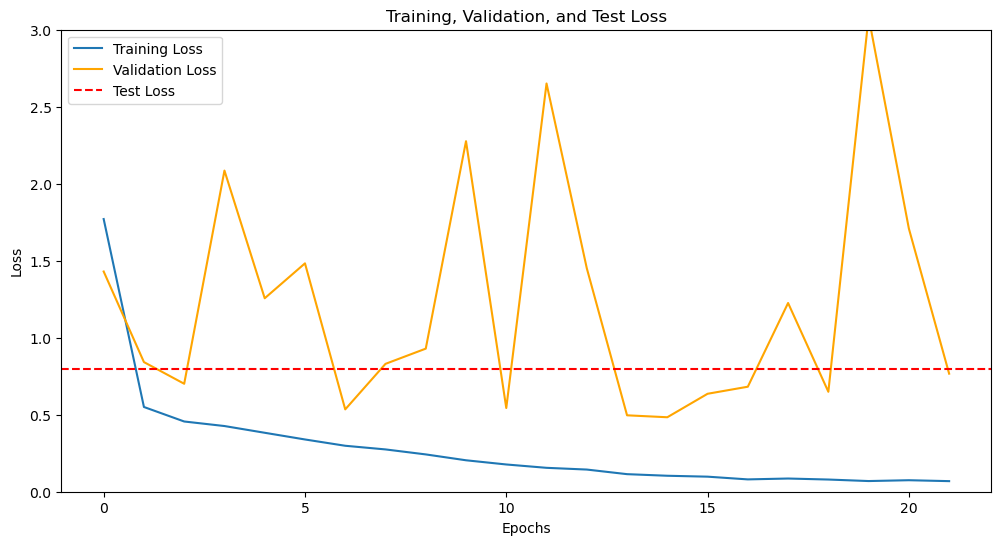

In [16]:
model1 = tf.keras.Sequential([
    # Block 1
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same", input_shape=(200, 200, 1)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2)),

    # Block 2
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2)),

    # Block 3
    tf.keras.layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2)),

    # Dense Layer
    tf.keras.layers.Flatten(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(4, activation='softmax')],
    name='CNN-Multiclass_Classification')

model1.compile(optimizer='adam', loss=tf.keras.losses.CategoricalCrossentropy(), metrics=['accuracy'])

train_and_plot_layers(X_train, y_train, X_val, y_val, X_test, y_test, model1)

Epoch 1/50
695/695 [==============================] - 37s 48ms/step - loss: 1.1604 - accuracy: 0.6970 - val_loss: 0.8360 - val_accuracy: 0.6392
Epoch 2/50
695/695 [==============================] - 33s 48ms/step - loss: 0.5304 - accuracy: 0.7934 - val_loss: 6.6038 - val_accuracy: 0.1721
Epoch 3/50
695/695 [==============================] - 31s 45ms/step - loss: 0.4664 - accuracy: 0.8207 - val_loss: 0.6467 - val_accuracy: 0.7508
Epoch 4/50
695/695 [==============================] - 29s 41ms/step - loss: 0.4216 - accuracy: 0.8392 - val_loss: 0.7802 - val_accuracy: 0.7239
Epoch 5/50
695/695 [==============================] - 32s 47ms/step - loss: 0.3796 - accuracy: 0.8570 - val_loss: 0.4425 - val_accuracy: 0.8350
Epoch 6/50
695/695 [==============================] - 31s 44ms/step - loss: 0.3509 - accuracy: 0.8666 - val_loss: 0.7745 - val_accuracy: 0.7149
Epoch 7/50
695/695 [==============================] - 30s 43ms/step - loss: 0.3256 - accuracy: 0.8779 - val_loss: 0.9199 - val_accuracy:

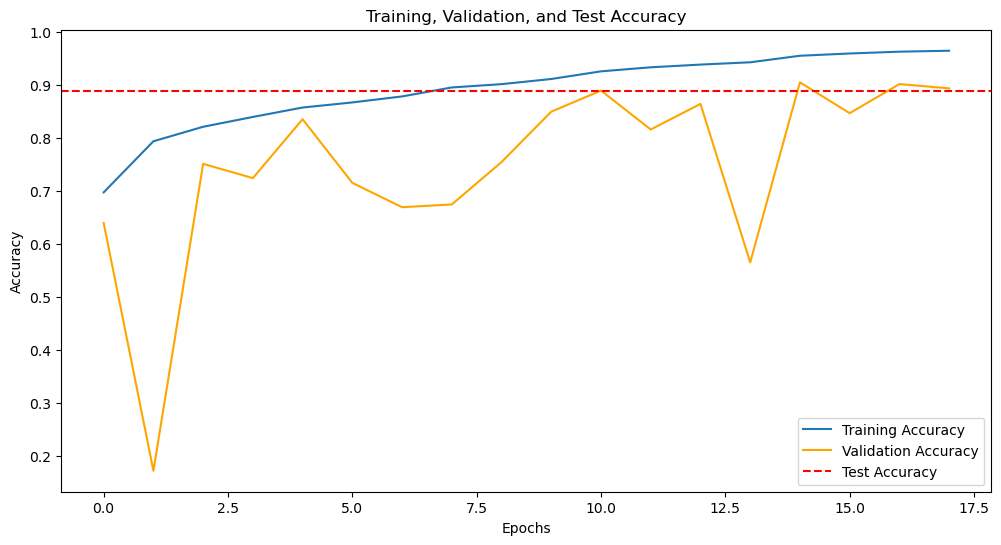

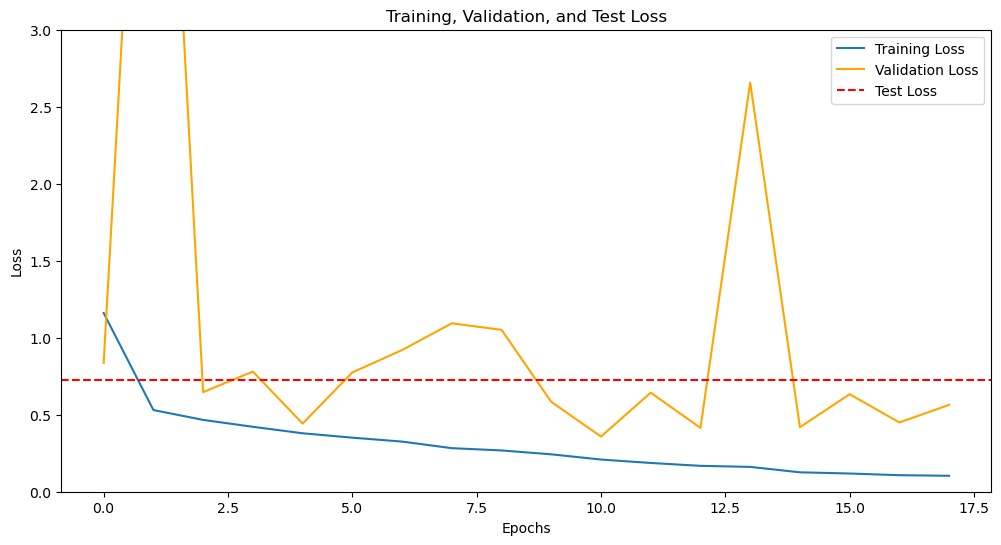

In [17]:
model2 = tf.keras.Sequential([
    # Block 1
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same", input_shape=(200, 200, 1)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2)),

    # Block 2
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2)),

    # Block 3
    tf.keras.layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2)),

    # Block 4
    tf.keras.layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2)),

    # Block 5
    tf.keras.layers.Flatten(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(4, activation='softmax')],
    name='CNN-Multiclass_Classification')

model2.compile(optimizer='adam', loss=tf.keras.losses.CategoricalCrossentropy(), metrics=['accuracy'])

train_and_plot_layers(X_train, y_train, X_val, y_val, X_test, y_test, model2)

Epoch 1/50
695/695 [==============================] - 62s 76ms/step - loss: 1.2545 - accuracy: 0.5000 - val_loss: 0.9692 - val_accuracy: 0.6208
Epoch 2/50
695/695 [==============================] - 54s 78ms/step - loss: 0.8743 - accuracy: 0.6507 - val_loss: 2.6423 - val_accuracy: 0.5087
Epoch 3/50
695/695 [==============================] - 52s 74ms/step - loss: 0.7971 - accuracy: 0.6789 - val_loss: 1.2354 - val_accuracy: 0.5182
Epoch 4/50
695/695 [==============================] - 52s 74ms/step - loss: 0.7341 - accuracy: 0.7066 - val_loss: 0.9089 - val_accuracy: 0.6397
Epoch 5/50
695/695 [==============================] - 54s 78ms/step - loss: 0.6468 - accuracy: 0.7500 - val_loss: 1.0961 - val_accuracy: 0.6000
Epoch 6/50
695/695 [==============================] - 51s 73ms/step - loss: 0.5861 - accuracy: 0.7784 - val_loss: 1.3251 - val_accuracy: 0.5527
Epoch 7/50
695/695 [==============================] - 54s 78ms/step - loss: 0.5053 - accuracy: 0.8136 - val_loss: 0.4229 - val_accuracy:

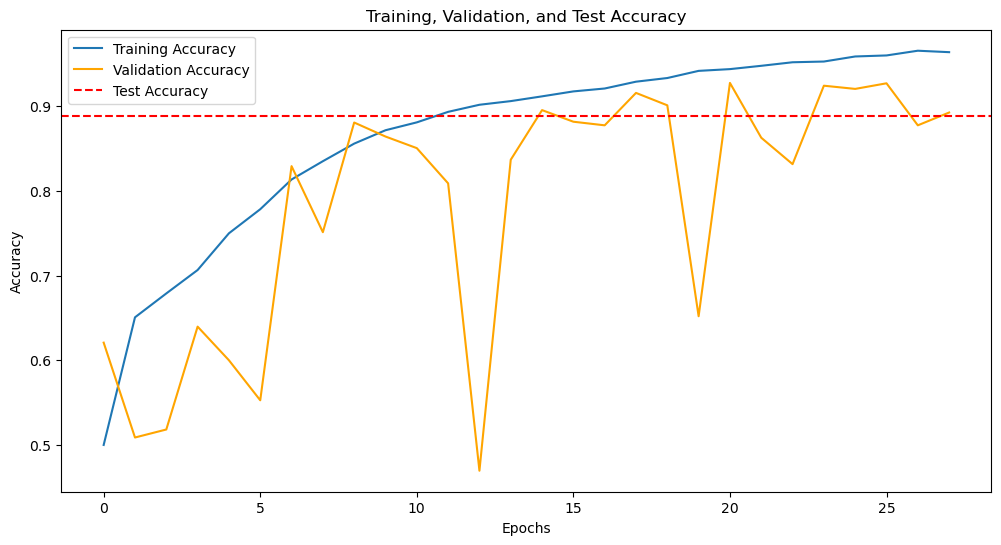

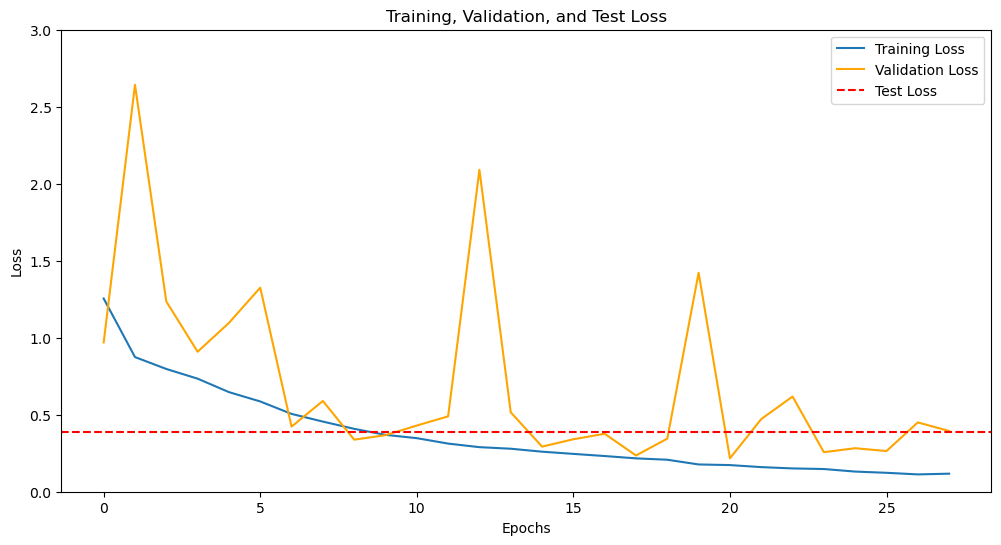

In [18]:
model3 = tf.keras.Sequential([
    # Block 1
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same", input_shape=(200, 200, 1)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2)),

    # Block 2
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2)),

    # Block 3
    tf.keras.layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2)),

    # Block 4
    tf.keras.layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2)),

    # Block 5
    tf.keras.layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Block 6
    tf.keras.layers.AveragePooling2D((4, 4), padding='same'),
    tf.keras.layers.Reshape((-1, 512)),
    tf.keras.layers.LSTM(100, activation='relu', return_sequences=True, recurrent_dropout=0.5, dropout=0.5),
    tf.keras.layers.LSTM(50, activation='relu', return_sequences=False, recurrent_dropout=0.5, dropout=0.5),
    tf.keras.layers.Flatten(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(4, activation='softmax')],
    name='CNN-LSTM_Multiclass_Classification')

model3.compile(optimizer='adam', loss=tf.keras.losses.CategoricalCrossentropy(), metrics=['accuracy'])

train_and_plot_layers(X_train, y_train, X_val, y_val, X_test, y_test, model3)

<a name="sampling"></a>
### 5.2 Sampling

In [15]:
model4 = tf.keras.Sequential([
    # Block 1
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same", input_shape=(200, 200, 1)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2)),

    # Block 2
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2)),

    # Block 3
    tf.keras.layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2)),

    # Block 4
    tf.keras.layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2)),

    # Block 5
    tf.keras.layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.Conv2D(512, (3, 3), activation='relu', padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Block 6
    tf.keras.layers.AveragePooling2D((4, 4), padding='same'),
    tf.keras.layers.Reshape((-1, 512)),
    tf.keras.layers.LSTM(100, activation='relu', return_sequences=True, recurrent_dropout=0.5, dropout=0.5),
    tf.keras.layers.LSTM(50, activation='relu', return_sequences=False, recurrent_dropout=0.5, dropout=0.5),
    tf.keras.layers.Flatten(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(4, activation='softmax')],
    name='CNN-LSTM_Multiclass_Classification')

2023-08-04 15:05:52.052689: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-08-04 15:05:55.164242: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1613] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 78977 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:01:00.0, compute capability: 8.0
2023-08-04 15:05:55.165652: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1613] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 78977 MB memory:  -> device: 1, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:81:00.0, compute capability: 8.0


In [59]:
def train_and_plot_sampling(X_train, y_train, X_val, y_val, X_test, y_test, model):
    
    X_train_flat = X_train.reshape(X_train.shape[0], -1)
    X_val_flat = X_val.reshape(X_val.shape[0], -1)

    # Führe SMOTE-Überabtastung auf den 2D-Arrays durch
    smote = SMOTE(sampling_strategy='auto')
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train_flat, y_train)

    # Forme die Daten zurück in das ursprüngliche 4D-Format
    X_train_resampled = X_train_resampled.reshape(-1, X_train.shape[1], X_train.shape[2], X_train.shape[3])
    model = tf.keras.models.clone_model(model)
    model.compile(optimizer='adam', loss=tf.keras.losses.CategoricalCrossentropy(), metrics=['accuracy'])
    history_with_combination = model.fit(X_train_resampled, y_train_resampled, batch_size=32, epochs=50, validation_data=(X_val, y_val), callbacks=[early_stopping])
    
    # Train without any sampling
    model.compile(optimizer='adam', loss=tf.keras.losses.CategoricalCrossentropy(), metrics=['accuracy'])
    history_without_sampling = model.fit(X_train, y_train, batch_size=32, epochs=50, validation_data=(X_val, y_val), callbacks=[early_stopping])

    # Plotting
    plt.figure(figsize=(18, 12))
    plt.subplot(1, 2, 1)
    plt.plot(history_without_sampling.history['accuracy'], label='Training Accuracy')
    plt.plot(history_without_sampling.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training Without Sampling')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history_with_combination.history['accuracy'], label='Training Accuracy')
    plt.plot(history_with_combination.history['val_accuracy'], label='Validation Accuracy')
    plt.axhline(y_test, color='r', linestyle='dashed', label='Test Accuracy')  # Horizontal line for test accuracy
    plt.title('Training With Combination of Oversampling and Undersampling')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    # Evaluate on the test set and plot the test accuracy
    test_loss, test_accuracy = model.evaluate(X_test, y_test)
    print("Test Loss:", test_loss)
    print("Test Accuracy:", test_accuracy)

    plt.figure(figsize=(12, 6))
    plt.plot(history_with_combination.history['accuracy'], label='Training Accuracy')
    plt.plot(history_with_combination.history['val_accuracy'], label='Validation Accuracy')
    plt.axhline(test_accuracy, color='r', linestyle='dashed', label='Test Accuracy')  # Horizontal line for test accuracy
    plt.title('Training With Combination of Oversampling and Undersampling')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

Epoch 1/50
1338/1338 [==============================] - 101s 69ms/step - loss: 0.9587 - accuracy: 0.6179 - val_loss: 0.7662 - val_accuracy: 0.6657
Epoch 2/50
1338/1338 [==============================] - 90s 68ms/step - loss: 0.5523 - accuracy: 0.7953 - val_loss: 0.7800 - val_accuracy: 0.6898
Epoch 3/50
1338/1338 [==============================] - 91s 68ms/step - loss: 0.4153 - accuracy: 0.8557 - val_loss: 0.8121 - val_accuracy: 0.6941
Epoch 4/50
1338/1338 [==============================] - 91s 68ms/step - loss: 0.3322 - accuracy: 0.8844 - val_loss: 0.5592 - val_accuracy: 0.7839
Epoch 5/50
1338/1338 [==============================] - 90s 68ms/step - loss: 0.2886 - accuracy: 0.9032 - val_loss: 0.3303 - val_accuracy: 0.8832
Epoch 6/50
1338/1338 [==============================] - 91s 68ms/step - loss: 0.2493 - accuracy: 0.9164 - val_loss: 1.2940 - val_accuracy: 0.6303
Epoch 7/50
1338/1338 [==============================] - 90s 68ms/step - loss: 0.2216 - accuracy: 0.9266 - val_loss: 0.7000 

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

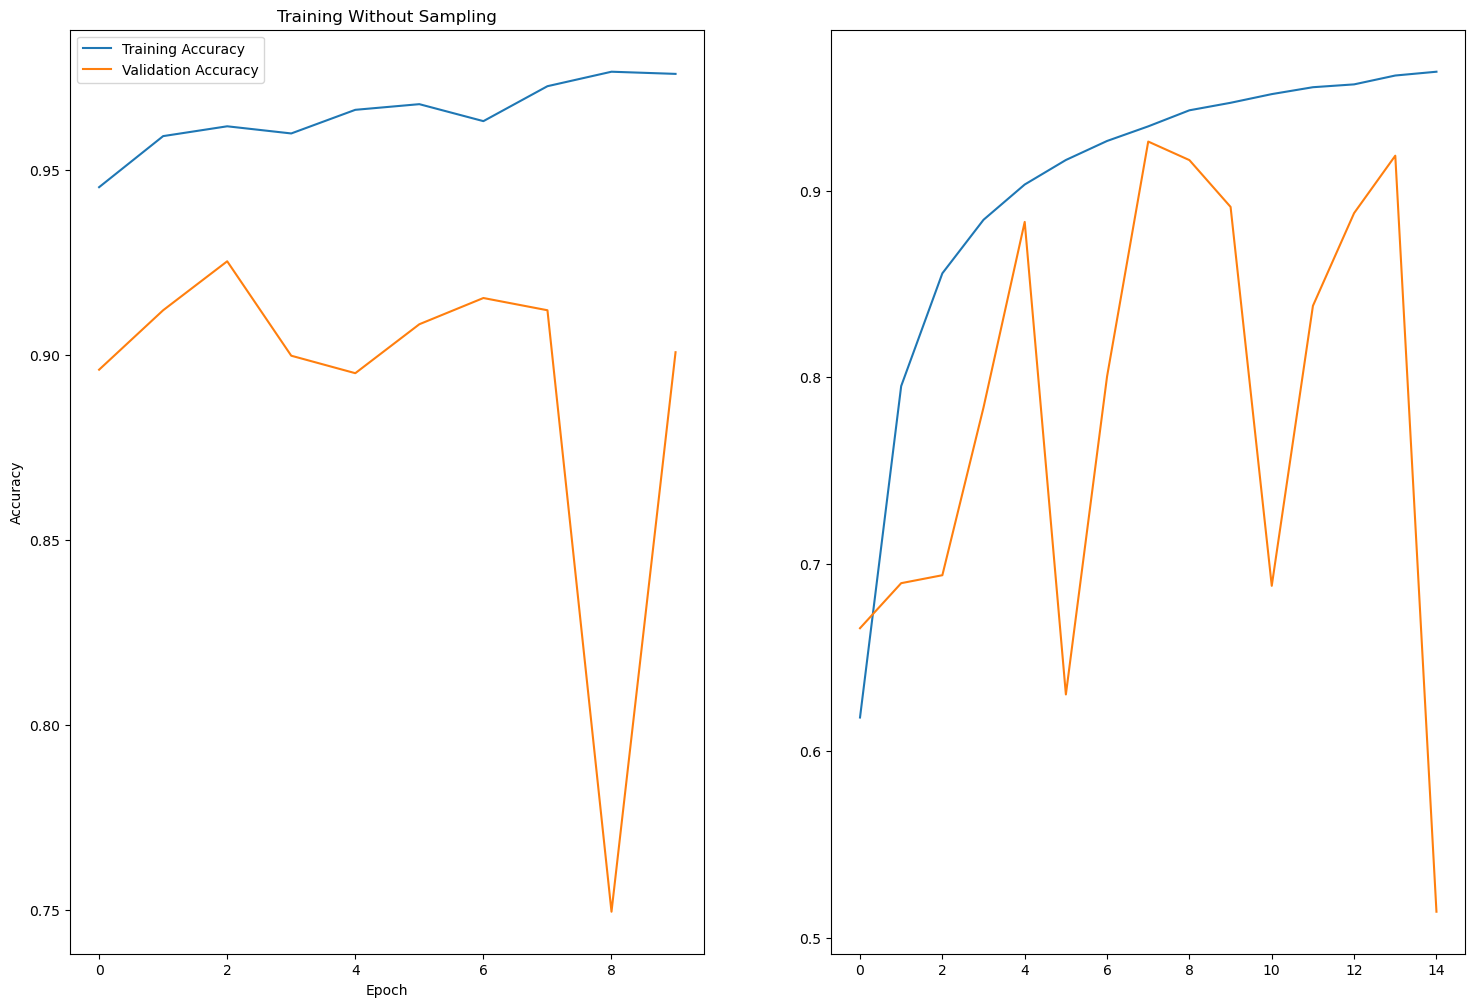

In [60]:
train_and_plot_sampling(X_train, y_train, X_val, y_val, X_test, y_test, model4)

<a name="Hyperparameter"></a>
### 5.3 Hyperparameter

In [12]:
hyp_configs = [
    {'num_filters': [64, 64, 128, 128, 256, 256, 512], 'dropout_rate': 0.2, 'batch_size': 64, 'epochs': 50, 'learning_rate': 0.001},
    {'num_filters': [32, 32, 64, 64, 128, 128, 256], 'dropout_rate': 0.3, 'batch_size': 32, 'epochs': 100, 'learning_rate': 0.001},
    {'num_filters': [128, 128, 256, 256, 512, 512, 512], 'dropout_rate': 0.5, 'batch_size': 128, 'epochs': 50, 'learning_rate': 0.0001}]

In [23]:
val_accuracies = []
losses_list = []
accuracies_list = []
training_times = []
test_losses_list = []
test_accuracies_list = []
history_list = []

In [24]:
for i, config in enumerate(hyp_configs):
    model5 = tf.keras.Sequential([
        # Block 1
        tf.keras.layers.Conv2D(config['num_filters'][0], (3, 3), activation = 'relu', padding = 'same', input_shape = (200, 200, 1)),
        tf.keras.layers.Conv2D(config['num_filters'][1], (3, 3), activation = 'relu', padding = 'same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D((2, 2), strides = (2, 2)),

        # Block 2
        tf.keras.layers.Conv2D(config['num_filters'][2], (3, 3), activation = 'relu', padding = 'same'),
        tf.keras.layers.Conv2D(config['num_filters'][3], (3, 3), activation = 'relu', padding = 'same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D((2, 2), strides = (2, 2)),

        # Block 3
        tf.keras.layers.Conv2D(config['num_filters'][4], (3, 3), activation = 'relu', padding = 'same'),
        tf.keras.layers.Conv2D(config['num_filters'][5], (3, 3), activation = 'relu', padding = 'same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D((2, 2), strides = (2, 2)),

        # Block 4
        tf.keras.layers.Conv2D(config['num_filters'][6], (3, 3), activation = 'relu', padding = 'same'),
        tf.keras.layers.Conv2D(config['num_filters'][6], (3, 3), activation = 'relu', padding = 'same'),
        tf.keras.layers.Conv2D(config['num_filters'][6], (3, 3), activation = 'relu', padding = 'same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D((2, 2), strides = (2, 2)),

        # Block 5
        tf.keras.layers.Conv2D(config['num_filters'][6], (3, 3), activation = 'relu', padding = 'same'),
        tf.keras.layers.Conv2D(config['num_filters'][6], (3, 3), activation = 'relu', padding = 'same'),
        tf.keras.layers.Conv2D(config['num_filters'][6], (3, 3), activation = 'relu', padding = 'same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D((2, 2)),

        #Block 6
        tf.keras.layers.AveragePooling2D((4, 4), padding = 'same'),
        tf.keras.layers.Reshape((-1, config['num_filters'][6])),
        tf.keras.layers.LSTM(100, activation='relu', return_sequences=True, recurrent_dropout=0.5, dropout=0.5),
        tf.keras.layers.LSTM(50, activation='relu', return_sequences=False, recurrent_dropout=0.5, dropout=0.5),
        tf.keras.layers.Flatten(),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(config['dropout_rate']),
        tf.keras.layers.Dense(num_classes, activation = 'softmax')],
        name = 'CNN-LSTM_Multiclass_Classification')

    optimizer = tf.keras.optimizers.Adam(learning_rate=config['learning_rate'])
    model5.compile(optimizer=optimizer, loss=tf.keras.losses.CategoricalCrossentropy(), metrics=['accuracy'])

    start_time = time.time()

    history = model5.fit(X_train, y_train, batch_size=config['batch_size'], epochs=config['epochs'], validation_data=(X_val, y_val), callbacks=[early_stopping])
    history_list.append(history)  # History für diesen Durchlauf speichern
    
    training_time = time.time() - start_time
    training_times.append(training_time)

    losses_list.append(history.history['loss'])
    accuracies_list.append(history.history['accuracy'])
    val_accuracies.append(history.history['val_accuracy'])  # Füge die Validierungs-Genauigkeiten hinzu


    # Evaluate the model on the test set and save test results
    test_loss, test_accuracy = model5.evaluate(X_test, y_test)
    test_losses_list.append(test_loss)
    test_accuracies_list.append(test_accuracy)

Epoch 1/50
348/348 [==============================] - 44s 102ms/step - loss: 1.1777 - accuracy: 0.5524 - val_loss: 7.1182 - val_accuracy: 0.2842
Epoch 2/50
348/348 [==============================] - 35s 100ms/step - loss: 0.7838 - accuracy: 0.6927 - val_loss: 2.3139 - val_accuracy: 0.4988
Epoch 3/50
348/348 [==============================] - 35s 100ms/step - loss: 0.6230 - accuracy: 0.7634 - val_loss: 0.6877 - val_accuracy: 0.7338
Epoch 4/50
348/348 [==============================] - 35s 101ms/step - loss: 0.4890 - accuracy: 0.8206 - val_loss: 2.7273 - val_accuracy: 0.3868
Epoch 5/50
348/348 [==============================] - 35s 101ms/step - loss: 0.3966 - accuracy: 0.8537 - val_loss: 0.7540 - val_accuracy: 0.7229
Epoch 6/50
348/348 [==============================] - 34s 99ms/step - loss: 0.3531 - accuracy: 0.8730 - val_loss: 0.8328 - val_accuracy: 0.7395
Epoch 7/50
348/348 [==============================] - 36s 102ms/step - loss: 0.3173 - accuracy: 0.8855 - val_loss: 0.6159 - val_acc

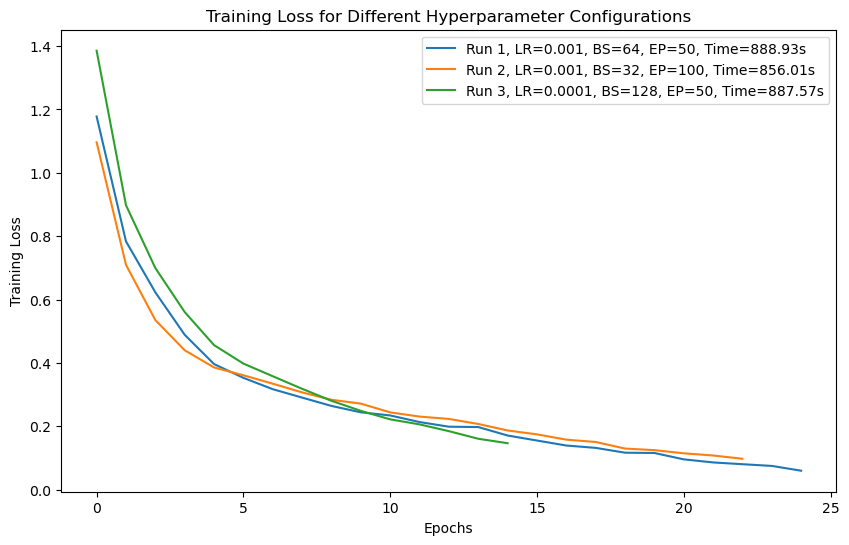

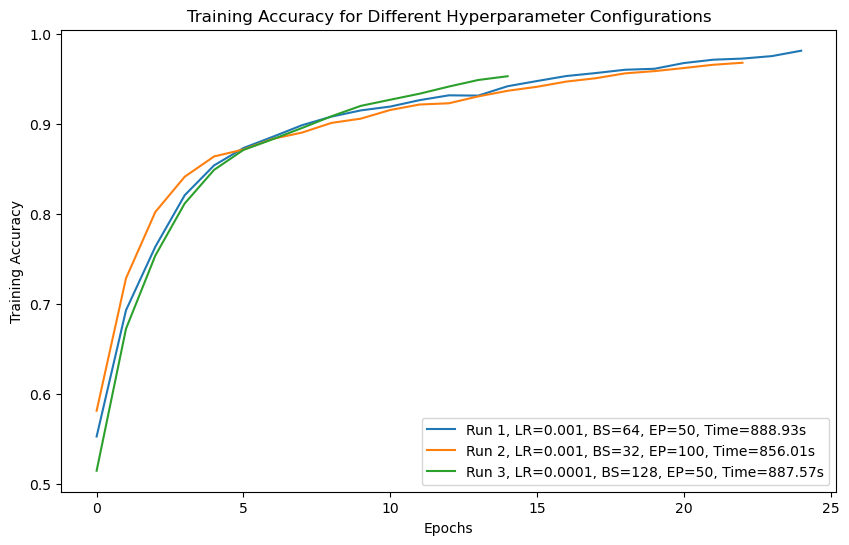

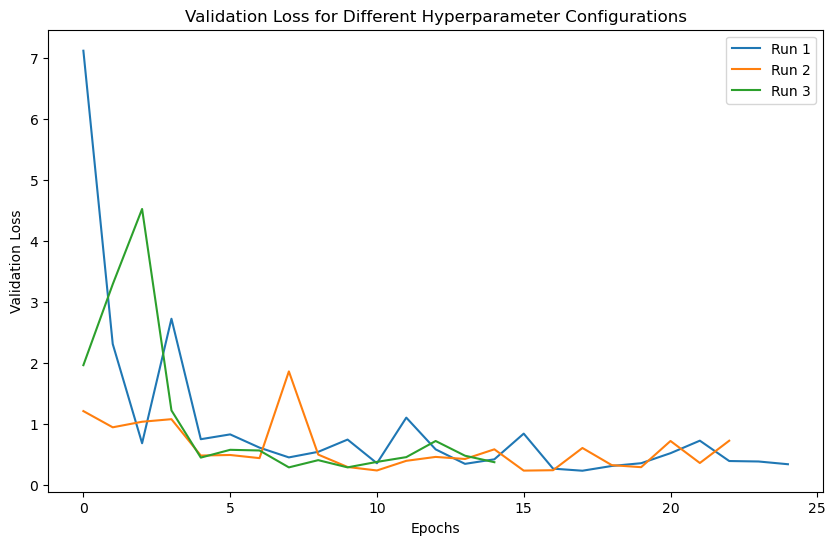

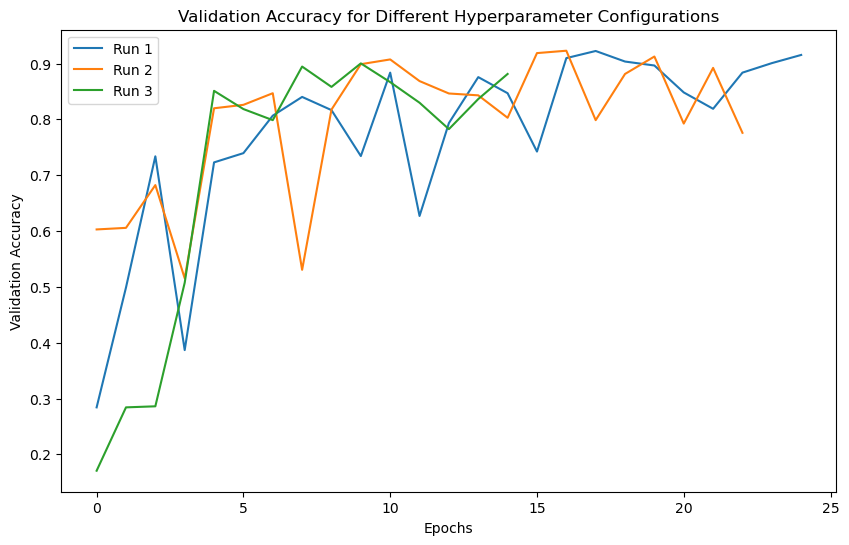

+-------+---------------+------------+--------+---------------------+--------------------+
|  Run  | Learning Rate | Batch Size | Epochs |      Test Loss      |   Test Accuracy    |
+-------+---------------+------------+--------+---------------------+--------------------+
| Run 1 |     0.001     |     64     |   50   | 0.31713756918907166 | 0.9154064059257507 |
| Run 2 |     0.001     |     32     |  100   | 0.7539424896240234  | 0.7705576419830322 |
| Run 3 |    0.0001     |    128     |   50   | 0.3865135610103607  | 0.8719281554222107 |
+-------+---------------+------------+--------+---------------------+--------------------+


In [29]:
plt.figure(figsize=(10, 6))
for i, config in enumerate(hyp_configs):
    plt.plot(losses_list[i], label=f"Run {i+1}, LR={config['learning_rate']}, BS={config['batch_size']}, EP={config['epochs']}, Time={training_times[i]:.2f}s")
plt.xlabel('Epochs')
plt.ylabel('Training Loss')
plt.legend()
plt.title('Training Loss for Different Hyperparameter Configurations')
plt.show()

plt.figure(figsize=(10, 6))
for i, config in enumerate(hyp_configs):
    plt.plot(accuracies_list[i], label=f"Run {i+1}, LR={config['learning_rate']}, BS={config['batch_size']}, EP={config['epochs']}, Time={training_times[i]:.2f}s")
plt.xlabel('Epochs')
plt.ylabel('Training Accuracy')
plt.legend()
plt.title('Training Accuracy for Different Hyperparameter Configurations')
plt.show()

plt.figure(figsize=(10, 6))
for i, config in enumerate(hyp_configs):
    plt.plot(history_list[i].history['val_loss'], label=f"Run {i+1}")
plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.legend()
plt.title('Validation Loss for Different Hyperparameter Configurations')
plt.show()

# ... (dein vorheriger Code)

# Plot der Validierungs-Genauigkeiten für verschiedene Hyperparameter-Konfigurationen
plt.figure(figsize=(10, 6))
for i, config in enumerate(hyp_configs):
    plt.plot(val_accuracies[i], label=f"Run {i+1}")
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.title('Validation Accuracy for Different Hyperparameter Configurations')
plt.show()

# ... (Rest deines Codes)




table_data = []
for i, config in enumerate(hyp_configs):
    row = [f"Run {i+1}", config['learning_rate'], config['batch_size'], config['epochs'], test_losses_list[i], test_accuracies_list[i]]
    table_data.append(row)

headers = ["Run", "Learning Rate", "Batch Size", "Epochs", "Test Loss", "Test Accuracy"]
table = tabulate(table_data, headers=headers, tablefmt="pretty")
print(table)


In [30]:
print(val_accuracies)

[[0.2841607630252838, 0.49881798028945923, 0.7338061332702637, 0.38676121830940247, 0.722931444644928, 0.7394798994064331, 0.80661940574646, 0.8401890993118286, 0.8165484666824341, 0.7342789769172668, 0.8836879730224609, 0.6269503831863403, 0.793380618095398, 0.8756501078605652, 0.8468084931373596, 0.7423167824745178, 0.909692645072937, 0.9224586486816406, 0.9035460948944092, 0.8964539170265198, 0.8482269644737244, 0.8189125061035156, 0.8836879730224609, 0.9007092118263245, 0.9153664112091064], [0.6028369069099426, 0.6056737303733826, 0.6822695136070251, 0.5153664350509644, 0.8198581337928772, 0.8260047435760498, 0.8468084931373596, 0.5304964780807495, 0.8174940943717957, 0.8988179564476013, 0.9073286056518555, 0.8685579299926758, 0.8463357090950012, 0.8430259823799133, 0.8028368949890137, 0.9186761379241943, 0.922931432723999, 0.7985815405845642, 0.8813238739967346, 0.9125295281410217, 0.7924349904060364, 0.8921985626220703, 0.7758865356445312], [0.1706855744123459, 0.2841607630252838

<a name="auswertung"></a>
## 6. Auswertung

<a name="quellen"></a>
## 7. Quellen

[1] Al‐Amidie, Al‐Dujaili, Al‐Shamma, Alzubaidi, Duan, Fadhel, Farhan, Humaidi, Santamaría, Zhang (2021): Review of deep learning: concepts, CNN architectures, challenges, applications, future directions. In: Journal of Big Data. S. 14 ff.
[2] Ng (o. J.): Regularizing neural networks. https://www.deeplearning.ai/ai-notes/regularization/index.html (letzter Zugriff: 31.07.2023)